# Supervised prediction of known perturbation states

This notebook tests whether a simple Ridge model can outperform the no-change baseline for perturbations represented during training. Cells are split before canonical states are calculated, keeping the test measurements independent. One-hot perturbation labels cannot generalize to unseen perturbations; that is reserved for notebook 05.

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

DATA_PATH = "../data/raw/replogle22rpe1.h5ad"
MIN_CELLS = 100
N_COMPONENTS = 50
RANDOM_SEED = 42

adata = sc.read_h5ad(DATA_PATH)
print(adata)

AnnData object with n_obs × n_vars = 240774 × 8749
    obs: 'perturbation'


## Select quality-controlled perturbations

In [2]:
counts = adata.obs["perturbation"].value_counts().drop("control")
eligible_counts = counts[counts >= MIN_CELLS]
perturbations = eligible_counts.index.tolist()

print(f"Perturbations with at least {MIN_CELLS} cells: {len(perturbations)}")
print(eligible_counts.describe())

Perturbations with at least 100 cells: 783
count     783.000000
mean      195.823755
std       213.935053
min       100.000000
25%       118.000000
50%       145.000000
75%       193.000000
max      3580.000000
Name: count, dtype: float64


## Create independent train and test canonical states

For each perturbation, half of its cells estimate the training state and the other half estimate the held-out state.

In [3]:
rng = np.random.RandomState(RANDOM_SEED)
labels = adata.obs["perturbation"].to_numpy()

train_states = {}
test_states = {}

for perturbation in perturbations:
    positions = np.flatnonzero(labels == perturbation)
    shuffled = rng.permutation(positions)
    split_at = len(shuffled) // 2

    train_states[perturbation] = np.asarray(
        adata[shuffled[:split_at]].X.mean(axis=0)
    ).flatten()
    test_states[perturbation] = np.asarray(
        adata[shuffled[split_at:]].X.mean(axis=0)
    ).flatten()

train_state_df = pd.DataFrame(train_states, index=adata.var_names).T
test_state_df = pd.DataFrame(test_states, index=adata.var_names).T

control_positions = rng.permutation(np.flatnonzero(labels == "control"))
control_split = len(control_positions) // 2
train_control_state = np.asarray(
    adata[control_positions[:control_split]].X.mean(axis=0)
).flatten()
test_control_state = np.asarray(
    adata[control_positions[control_split:]].X.mean(axis=0)
).flatten()

print("Training state matrix:", train_state_df.shape)
print("Test state matrix:", test_state_df.shape)
print("Train/test cells overlap: no (split by position before averaging)")

Training state matrix: (783, 8749)
Test state matrix: (783, 8749)
Train/test cells overlap: no (split by position before averaging)


## Reduce the gene-expression output space

In [4]:
n_components = min(N_COMPONENTS, len(perturbations) - 1)
pca = PCA(n_components=n_components, random_state=RANDOM_SEED)
train_reduced = pca.fit_transform(train_state_df)

print("Reduced training state matrix:", train_reduced.shape)
print(f"Explained variance ({n_components} components): {pca.explained_variance_ratio_.sum():.2%}")

Reduced training state matrix: (783, 50)
Explained variance (50 components): 61.92%


/Users/mohammedismailzabiullah/Documents/Projects/mastersProject/virtual-cell-lab.worktrees/project-directory-structure-setup/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/mohammedismailzabiullah/Documents/Projects/mastersProject/virtual-cell-lab.worktrees/project-directory-structure-setup/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/mohammedismailzabiullah/Documents/Projects/mastersProject/virtual-cell-lab.worktrees/project-directory-structure-setup/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/mohammedismailzabiullah/Documents/Projects/mastersProject/virtual-cell-lab.worktrees/project-directory-structure-setup/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: Runtime

## Fit a one-hot Ridge model

Each row of the identity matrix is the one-hot encoding for one known perturbation. This model is a deliberately limited supervised baseline: it can learn known perturbation identities but cannot infer an unseen one.

In [5]:
perturbation_features = np.eye(len(perturbations))

model = Ridge(alpha=0.01)
model.fit(perturbation_features, train_reduced)

predicted_reduced = model.predict(perturbation_features)
predicted_states = pca.inverse_transform(predicted_reduced)

/Users/mohammedismailzabiullah/Documents/Projects/mastersProject/virtual-cell-lab.worktrees/project-directory-structure-setup/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/mohammedismailzabiullah/Documents/Projects/mastersProject/virtual-cell-lab.worktrees/project-directory-structure-setup/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/mohammedismailzabiullah/Documents/Projects/mastersProject/virtual-cell-lab.worktrees/project-directory-structure-setup/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/mohammedismailzabiullah/Documents/Projects/mastersProject/virtual-cell-lab.worktrees/project-directory-structure-setup/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:313: RuntimeWarning: divide by zero encountere

## Compare against the no-change baseline

Both models are evaluated against held-out canonical perturbation states in the original 8,749-gene space. The null model always predicts the training control state.

In [6]:
actual_states = test_state_df.to_numpy()
null_predictions = np.repeat(
    train_control_state[np.newaxis, :],
    len(perturbations),
    axis=0,
)

results = pd.DataFrame({
    "perturbation": perturbations,
    "cell_count": eligible_counts.loc[perturbations].to_numpy(),
    "null_mse": np.mean((actual_states - null_predictions) ** 2, axis=1),
    "ridge_mse": np.mean((actual_states - predicted_states) ** 2, axis=1),
})
results["improvement_percent"] = (
    (results["null_mse"] - results["ridge_mse"])
    / results["null_mse"]
    * 100
)

summary = pd.Series({
    "eligible_perturbations": len(results),
    "null_mse": mean_squared_error(actual_states, null_predictions),
    "ridge_mse": mean_squared_error(actual_states, predicted_states),
    "perturbations_improved": int((results["ridge_mse"] < results["null_mse"]).sum()),
    "median_improvement_percent": results["improvement_percent"].median(),
})

summary

eligible_perturbations        783.000000
null_mse                        0.005497
ridge_mse                       0.002436
perturbations_improved        609.000000
median_improvement_percent     20.316563
dtype: float64

In [7]:
results.sort_values("improvement_percent", ascending=False).head(10)

,perturbation,cell_count,null_mse,ridge_mse,improvement_percent
51,TIMM23B,348,0.021036,0.001154,94.514305
32,SMN2,424,0.027494,0.001560,94.327690
341,PRPF31,156,0.039486,0.002658,93.268654
382,PSMB5,147,0.050051,0.003433,93.141830
122,TRAPPC11,235,0.026826,0.001901,92.914383
26,SPC25,495,0.013435,0.000978,92.720600
56,EIF3CL,337,0.021014,0.001594,92.416285
766,SNRNP200,101,0.040588,0.003302,91.865679
73,C14orf178,292,0.028189,0.002428,91.387359
379,EIF2B2,148,0.024126,0.002213,90.827706


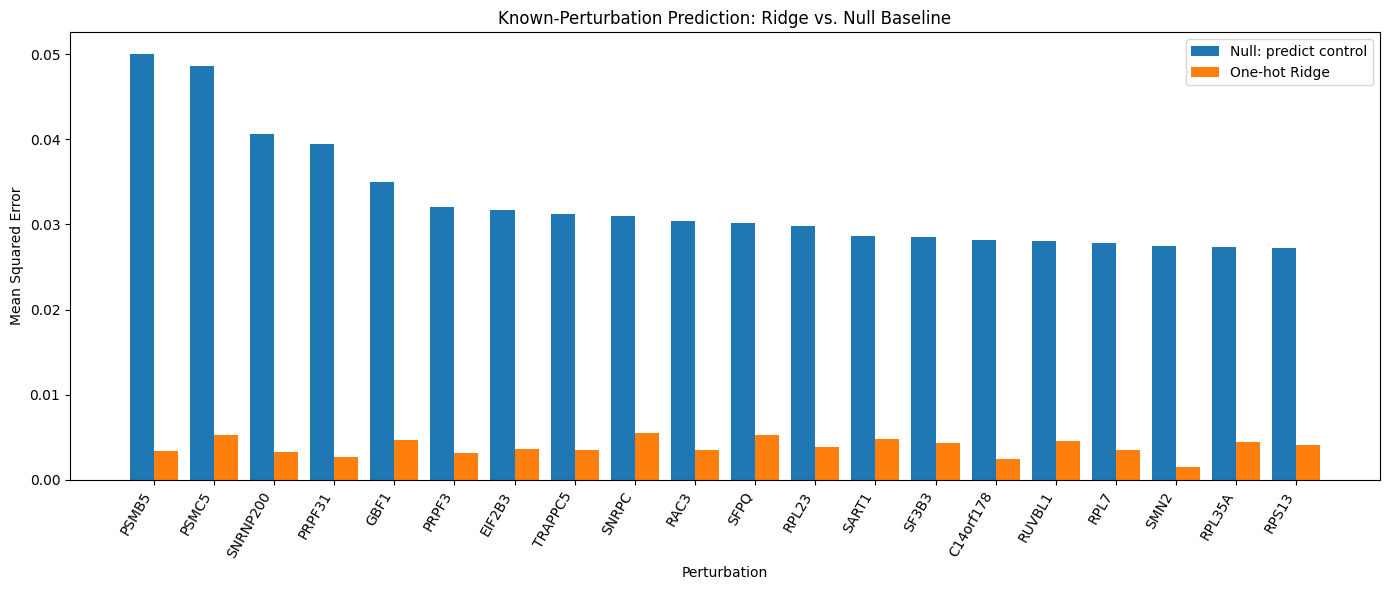

In [8]:
plot_results = results.sort_values("null_mse", ascending=False).head(20)
x = np.arange(len(plot_results))
width = 0.4

plt.figure(figsize=(14, 6))
plt.bar(x - width / 2, plot_results["null_mse"], width, label="Null: predict control")
plt.bar(x + width / 2, plot_results["ridge_mse"], width, label="One-hot Ridge")
plt.xticks(x, plot_results["perturbation"], rotation=60, ha="right")
plt.ylabel("Mean Squared Error")
plt.xlabel("Perturbation")
plt.title("Known-Perturbation Prediction: Ridge vs. Null Baseline")
plt.legend()
plt.tight_layout()
plt.show()